# Payment Fraud Detection with Cost-Aware ML — Final Version

**Goal:** Flag fraudulent online payments in a way that would hold up in a real bank, and report a number that can be trusted.

**What's new compared with version 4.** Version 4 caught 74.6% of fraud at a 1% false-alarm rate, but that number was optimistic. Three rules fix this:

| Rule | Version 4 | This version |
|---|---|---|
| Customer features | Used the customer's **future** payments too | Use **past payments only** (proved by a test) |
| Fraud labels | Known **1 day** after the fraud | Known **7 days** after the fraud (fixed before seeing any result) |
| Choices (settings, alert level) | Some compared on the test period | Made on **validation only**; test scored **once** |

The feature code lives in `src/features.py` so the notebook, the training script and the scoring script all use exactly the same logic. `tests/test_features.py` checks that no feature uses future data.

Same time split as every version: first 70% train, next 15% validation, last 15% test.

## Step 1 — Import Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import json
import gc
import warnings

from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

from src.features import load_data, build_features, feature_columns, category_columns, to_matrix, LABEL_DELAY_DAYS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

## Step 2 — Read Data & Time Split

In [2]:
# All payments, in time order
df = load_data("data")
df.shape

(590540, 434)

In [3]:
# First 70% train, next 15% validation, last 15% test
val_start = int(len(df) * 0.70)
test_start = int(len(df) * 0.85)

y = df["isFraud"].values
y_train, y_val, y_test = y[:val_start], y[val_start:test_start], y[test_start:]

In [4]:
# Payments and fraud rate in each period
pd.DataFrame({
    "Payments": [len(y_train), len(y_val), len(y_test)],
    "Fraud rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["Train", "Validation", "Test"]).round(4)

,Payments,Fraud rate
Train,413378,0.0352
Validation,88581,0.0343
Test,88581,0.0348


In [5]:
# Raw columns, kept for the leakage check in Step 4
raw_cols = df.columns.tolist()
raw_sample = df.loc[:149_999, raw_cols].copy()

## Step 3 — Build Features (past information only)

`build_features` runs these steps (see `src/features.py`):
1. **Basic:** hour, weekday, log amount, cents, and the `D` columns turned into fixed dates.
2. **Customer ID:** card + billing address + the date the card was first used (`day − D1`), plus looser keys (card + email, all card fields, device).
3. **30-day counts:** how many payments in the last 30 days share this card, email, device, customer, …
4. **Customer running statistics:** average and spread of amount, distances, `C`/`V` columns, and number of distinct emails/devices — over the customer's payments **so far**.
5. **Fraud history:** for each key, the number of earlier payments, frauds, fraud rate, most recent label and days since the last fraud — counting a label only once it is **at least 7 days old**.
6. **Velocity:** number and total amount of the key's earlier payments in the last hour, day and week.

In [6]:
# Labels count only once they are this old
LABEL_DELAY_DAYS

7

In [7]:
%%time
# Build every feature
df = build_features(df, y)

CPU times: user 7.87 s, sys: 129 ms, total: 8 s
Wall time: 8.05 s


In [8]:
# Model features and text (category) features
features = feature_columns(df)
cat_cols = category_columns(df, features)
len(features), len(cat_cols)

(569, 31)

In [9]:
# Check on the validation period: fraud rate by the customer's most recent known label (7+ days old)
df.loc[val_start:test_start - 1].groupby("hist_uid_last_label", dropna=False)["isFraud"].agg(["mean", "size"]).round(4)

,mean,size
hist_uid_last_label,,
0.0,0.0026,43085
1.0,0.8723,1057
NaN,0.0452,44439


Even with a 7-day delay, a customer whose most recent known payment was fraud is far more likely to be fraud again.

## Step 4 — Leakage Check

If any feature looked at the future, removing later payments would change the features of earlier ones. Build features on the first 150,000 payments and on the first 120,000, and compare the shared rows. (The same check runs in `tests/test_features.py`.)

In [10]:
# Features with and without the last 30,000 payments
sample_labels = raw_sample["isFraud"].values
with_future = build_features(raw_sample.copy(), sample_labels)
without_future = build_features(raw_sample.iloc[:120_000].copy(), sample_labels[:120_000])

In [11]:
# Number of feature values that differ in the shared 120,000 rows
shared = with_future.loc[:119_999, features]
diff = ~((shared == without_future[features]) | (shared.isna() & without_future[features].isna()))
int(diff.values.sum())

0

Zero differences: no feature uses information from later payments.

In [12]:
# Free the check data
del raw_sample, with_future, without_future, shared, diff
gc.collect()

0

## Step 5 — Feature Matrix

In [13]:
# Category lists from training + validation only (unseen values in the test period become missing)
categories = {col: sorted(df.loc[:test_start - 1, col].dropna().astype(str).unique()) for col in cat_cols}
df[cat_cols] = df[cat_cols].astype(str).where(df[cat_cols].notna())

In [14]:
# Amounts are needed for the cost step later
val_amounts = df["TransactionAmt"].values[val_start:test_start]
test_amounts = df["TransactionAmt"].values[test_start:]

In [15]:
# Features as one float32 array (the DataFrame is emptied column by column to save memory)
X = to_matrix(df, features, categories, drop=True)
cat_index = [features.index(col) for col in cat_cols]
del df
gc.collect()
X.shape

(590540, 569)

Rows are in time order, so each period is a block of rows. Slicing (`X[:val_start]`) gives a view of the array instead of a copy.

In [16]:
# Validation and test arrays (views, not copies)
X_val = X[val_start:test_start]
X_test = X[test_start:]

## Step 6 — Train with Early Stopping on the Validation Period

In [17]:
# Metrics used throughout the project
def evaluate(y_true, y_score):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return {
        "PR-AUC": average_precision_score(y_true, y_score),
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "Recall at 1% FPR": np.interp(0.01, fpr, tpr),
    }

In [18]:
# Tuned LightGBM settings (Optuna, second notebook) with learning rate 0.05
params = dict(
    objective="binary",
    learning_rate=0.05,
    num_leaves=367,
    min_child_samples=22,
    colsample_bytree=0.5,
    subsample=0.94,
    subsample_freq=1,
    reg_lambda=0.32,
    reg_alpha=0.02,
    metric="average_precision",
    seed=RANDOM_STATE,
    verbose=-1,
)

In [19]:
# LightGBM datasets
train_set = lgb.Dataset(X[:val_start], y_train, feature_name=features, categorical_feature=cat_index)
val_set = lgb.Dataset(X_val, y_val, reference=train_set)

In [20]:
%%time
# Train on the training period, stopping when validation PR-AUC stops improving
val_model = lgb.train(params, train_set, num_boost_round=6000, valid_sets=[val_set], callbacks=[lgb.early_stopping(150, verbose=False)])

CPU times: user 22min 37s, sys: 1.69 s, total: 22min 39s
Wall time: 11min 35s


In [21]:
# Number of trees kept
val_model.best_iteration

1254

In [22]:
# Validation results
val_scores = val_model.predict(X_val, num_iteration=val_model.best_iteration)
val_results = pd.Series(evaluate(y_val, val_scores)).round(4)
val_results

PR-AUC              0.7827
ROC-AUC             0.9642
Recall at 1% FPR    0.7071
dtype: float64

## Step 7 — Choose the Alert Levels on Validation

Both alert levels are written as **"flag the top x% of payments"**. A share carries over to the retrained model better than a raw score cut-off, and it is easy to run in production (for example, the review team checks the top 1.4% of each day's payments).
- **1% false-alarm level:** the share of payments that flags 1% of genuine validation payments.
- **Cost-optimal level:** the share with the lowest validation cost (missed fraud costs its amount, a false alarm costs $10).

In [23]:
# Share of payments to flag so that 1% of genuine validation payments are flagged
val_threshold = np.quantile(val_scores[y_val == 0], 0.99)
share_1pct_fpr = (val_scores >= val_threshold).mean()
round(share_1pct_fpr, 4)

np.float64(0.034)

In [24]:
# Total cost: missed fraud costs its amount, a false alarm costs $10
def total_cost(flagged, y_true, amounts, false_alarm_cost=10):
    missed_fraud = amounts[~flagged & (y_true == 1)].sum()
    false_alarms = (flagged & (y_true == 0)).sum()
    return missed_fraud + false_alarm_cost * false_alarms

In [25]:
# Validation cost when flagging the top 0.5% ... 30% of payments
flag_shares = np.round(np.arange(0.005, 0.3001, 0.005), 3)
val_costs = [total_cost(val_scores >= np.quantile(val_scores, 1 - share), y_val, val_amounts) for share in flag_shares]
share_cost_optimal = flag_shares[int(np.argmin(val_costs))]
share_cost_optimal

np.float64(0.105)

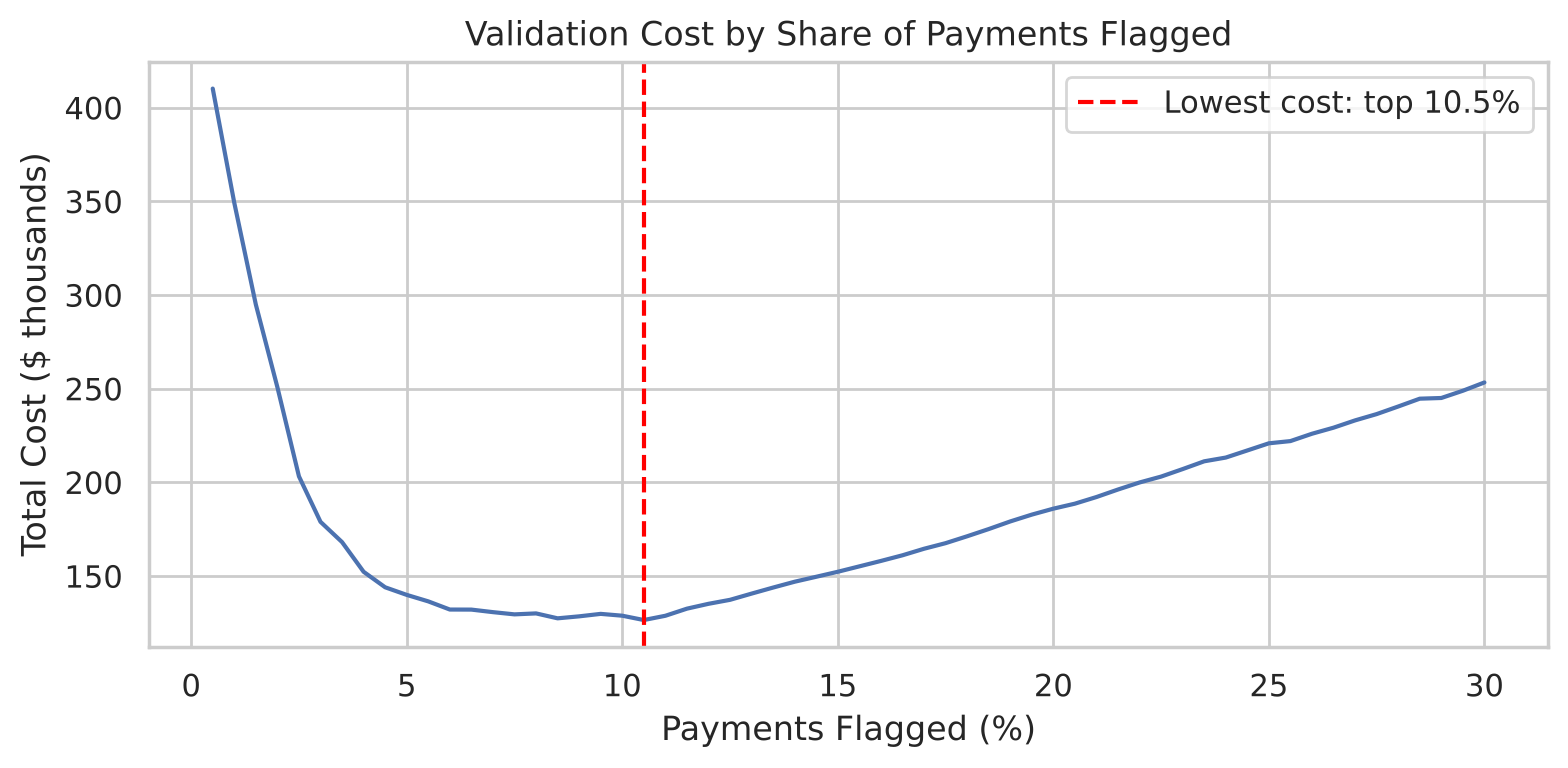

In [26]:
# Validation cost by flag share
plt.figure(figsize=(8, 4))
plt.plot(flag_shares * 100, np.array(val_costs) / 1000)
plt.axvline(share_cost_optimal * 100, color="red", linestyle="--", label=f"Lowest cost: top {share_cost_optimal:.1%}")
plt.title("Validation Cost by Share of Payments Flagged")
plt.xlabel("Payments Flagged (%)")
plt.ylabel("Total Cost ($ thousands)")
plt.legend()
plt.tight_layout()
plt.show()

## Step 8 — What Drives the Model

Total gain shows which features the trees rely on. SHAP values (`pred_contrib=True`, built into LightGBM) show how much each feature pushes individual predictions up or down.

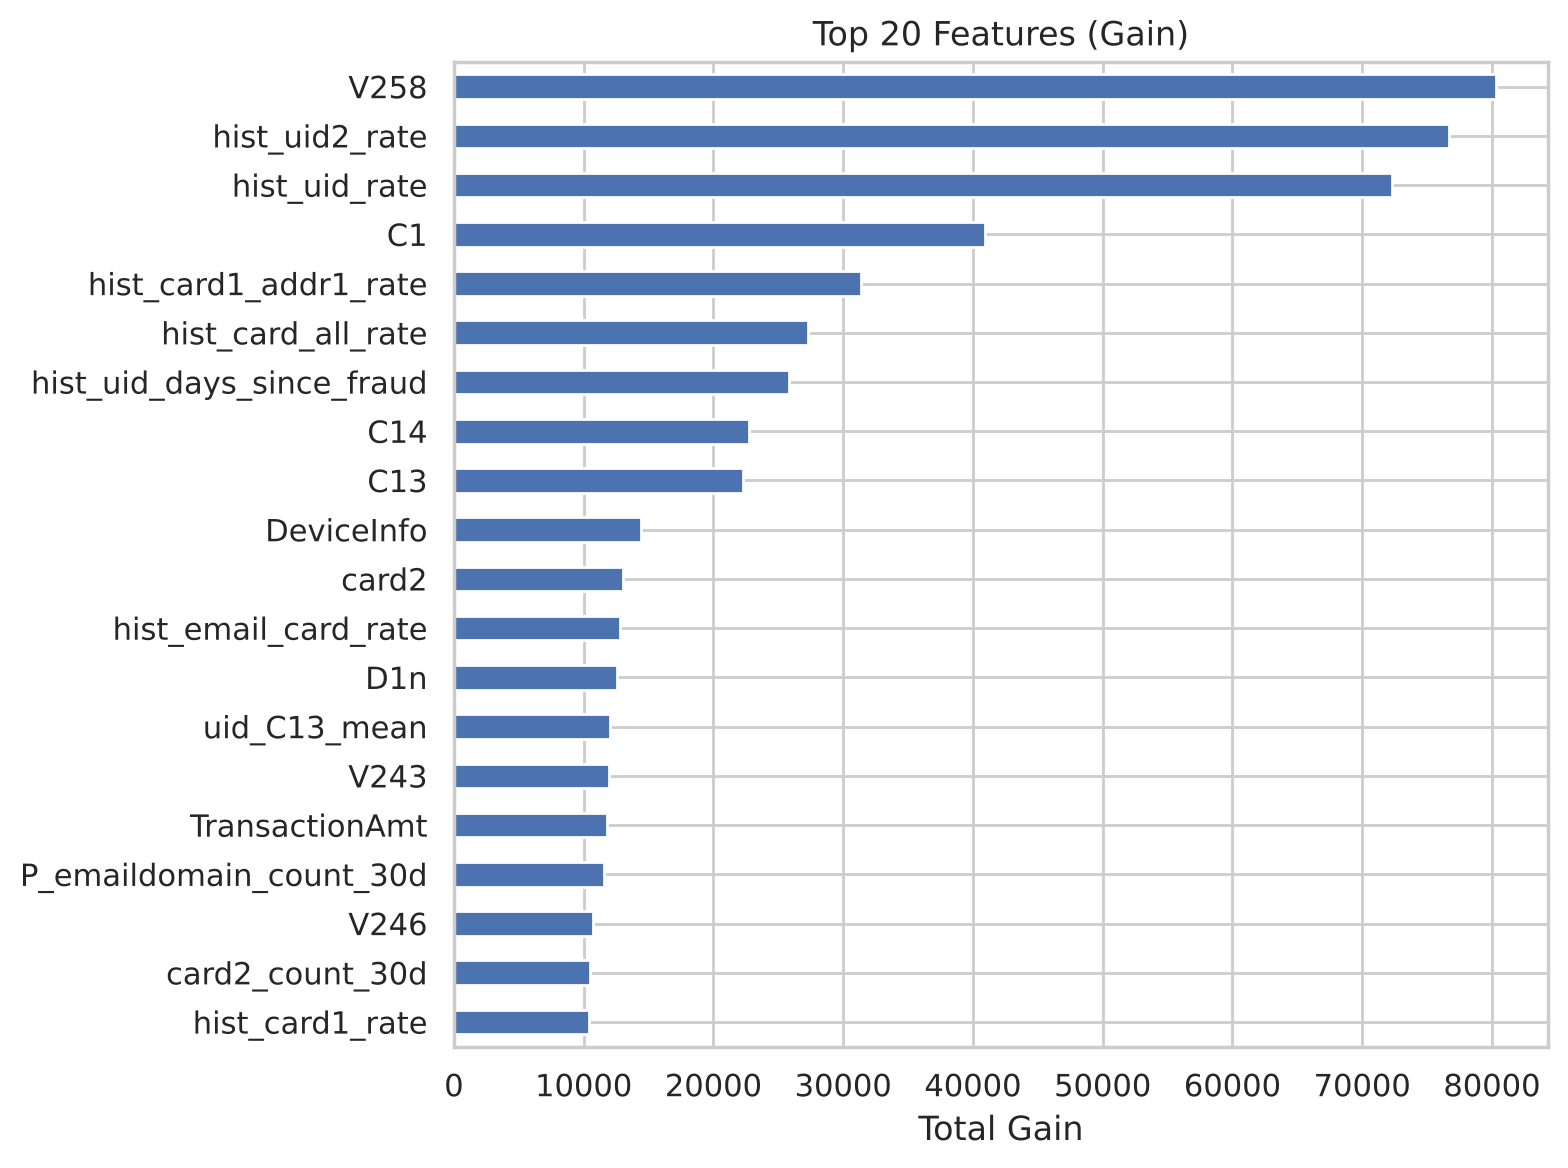

In [27]:
# Feature importance (total gain), top 20
importance = pd.Series(val_model.feature_importance("gain"), index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
importance.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 Features (Gain)")
plt.xlabel("Total Gain")
plt.tight_layout()
plt.show()

In [28]:
# SHAP values for 3,000 validation payments
rng = np.random.default_rng(RANDOM_STATE)
sample_rows = rng.choice(len(X_val), 3000, replace=False)
shap_values = val_model.predict(X_val[sample_rows], num_iteration=val_model.best_iteration, pred_contrib=True)[:, :-1]

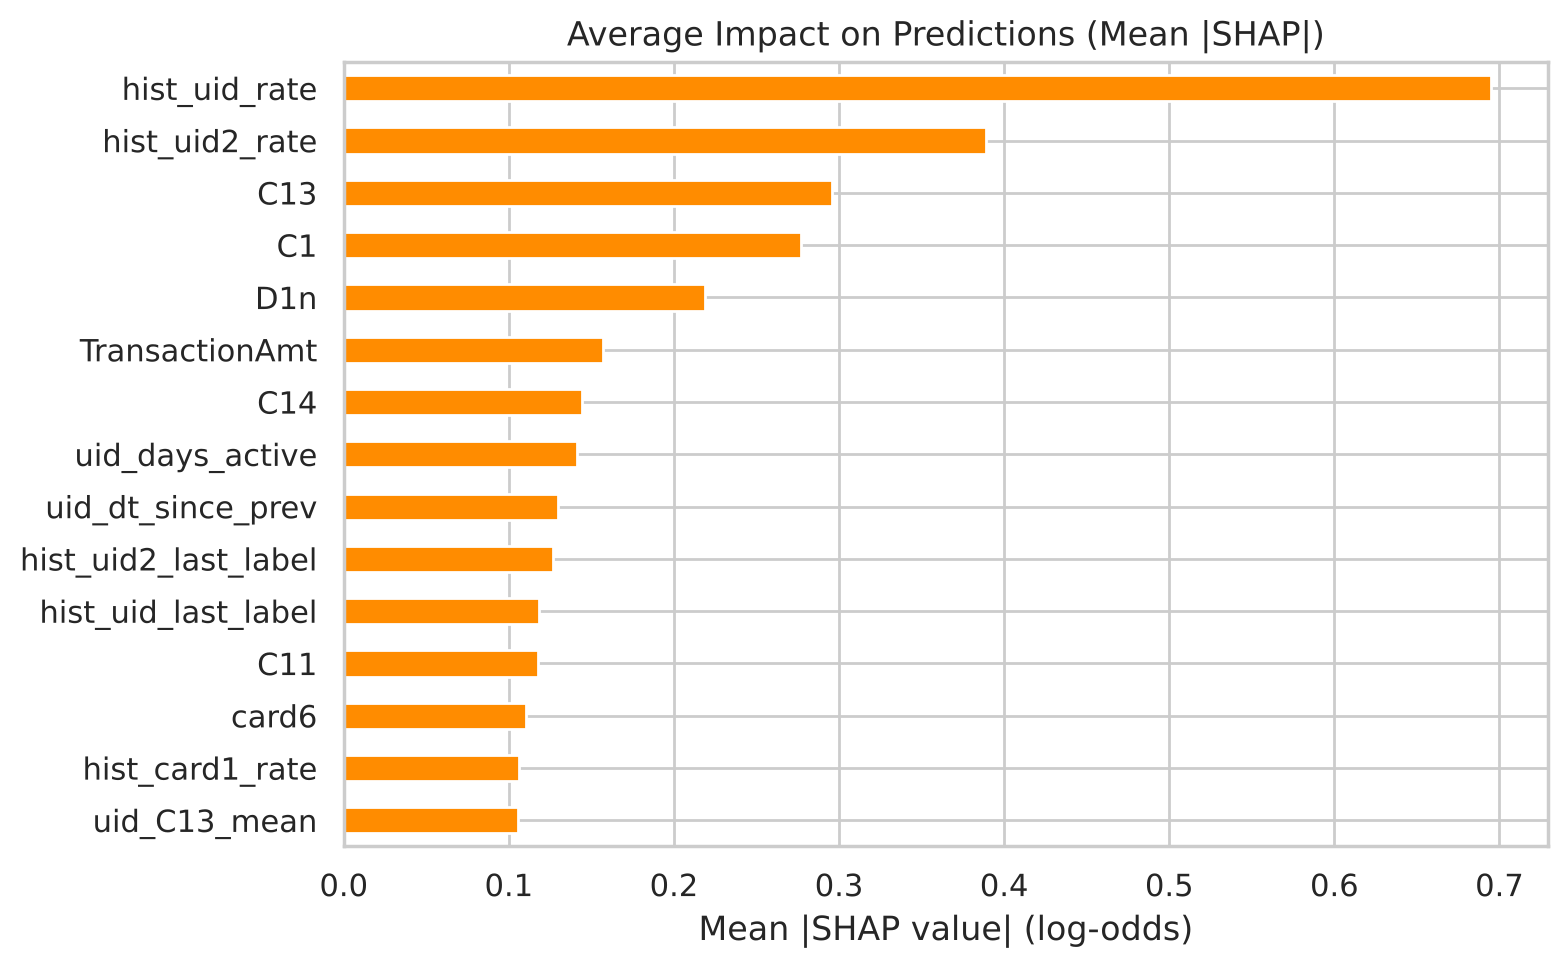

In [29]:
# Average absolute SHAP value, top 15 features
mean_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
mean_shap.head(15).sort_values().plot(kind="barh", color="darkorange")
plt.title("Average Impact on Predictions (Mean |SHAP|)")
plt.xlabel("Mean |SHAP value| (log-odds)")
plt.tight_layout()
plt.show()

In [30]:
# Free the first model
final_trees = int(val_model.best_iteration * 1.2)
del val_model, train_set, val_set, shap_values
gc.collect()

4089

## Step 9 — Final Model

Retrained on training + validation with a fixed number of trees (best validation count × 1.2).

In [31]:
# LightGBM dataset for training + validation
dev_set = lgb.Dataset(X[:test_start], y[:test_start], feature_name=features, categorical_feature=cat_index)

In [32]:
%%time
# Retrain on everything before the test period
final_model = lgb.train(params, dev_set, num_boost_round=final_trees)

CPU times: user 27min 10s, sys: 2.03 s, total: 27min 12s
Wall time: 13min 52s


## Step 10 — Test Period (scored once)

Nothing below changed any choice above.

In [33]:
# Test-period scores
test_scores = final_model.predict(X_test)

In [34]:
# Test-period results
test_results = pd.Series(evaluate(y_test, test_scores)).round(4)
test_results

PR-AUC              0.7441
ROC-AUC             0.9568
Recall at 1% FPR    0.6717
dtype: float64

In [35]:
# Test outcome of each alert policy (shares chosen on validation)
policies = {
    "Block nothing": test_scores > 1,
    "Default threshold 0.5": test_scores >= 0.5,
    f"Flag top {share_1pct_fpr:.2%} (1% false-alarm level)": test_scores >= np.quantile(test_scores, 1 - share_1pct_fpr),
    f"Flag top {share_cost_optimal:.1%} (cost-optimal)": test_scores >= np.quantile(test_scores, 1 - share_cost_optimal),
}

rows = []

for policy, flagged in policies.items():
    rows.append({
        "Policy": policy,
        "Flagged": flagged.sum(),
        "Fraud caught": (flagged & (y_test == 1)).sum(),
        "Share of fraud caught": round((flagged & (y_test == 1)).sum() / y_test.sum(), 3),
        "False-alarm rate": round((flagged & (y_test == 0)).sum() / (y_test == 0).sum(), 4),
        "Fraud $ caught": round(test_amounts[flagged & (y_test == 1)].sum()),
        "Total cost $": round(total_cost(flagged, y_test, test_amounts)),
    })

policy_table = pd.DataFrame(rows).set_index("Policy")
policy_table

,Flagged,Fraud caught,Share of fraud caught,False-alarm rate,Fraud $ caught,Total cost $
Policy,,,,,,
Block nothing,0,0,0.000,0.0000,0,469608
Default threshold 0.5,1830,1664,0.540,0.0019,185424,285844
Flag top 3.40% (1% false-alarm level),3008,2088,0.677,0.0108,252918,225891
Flag top 10.5% (cost-optimal),9301,2599,0.843,0.0784,367422,169206


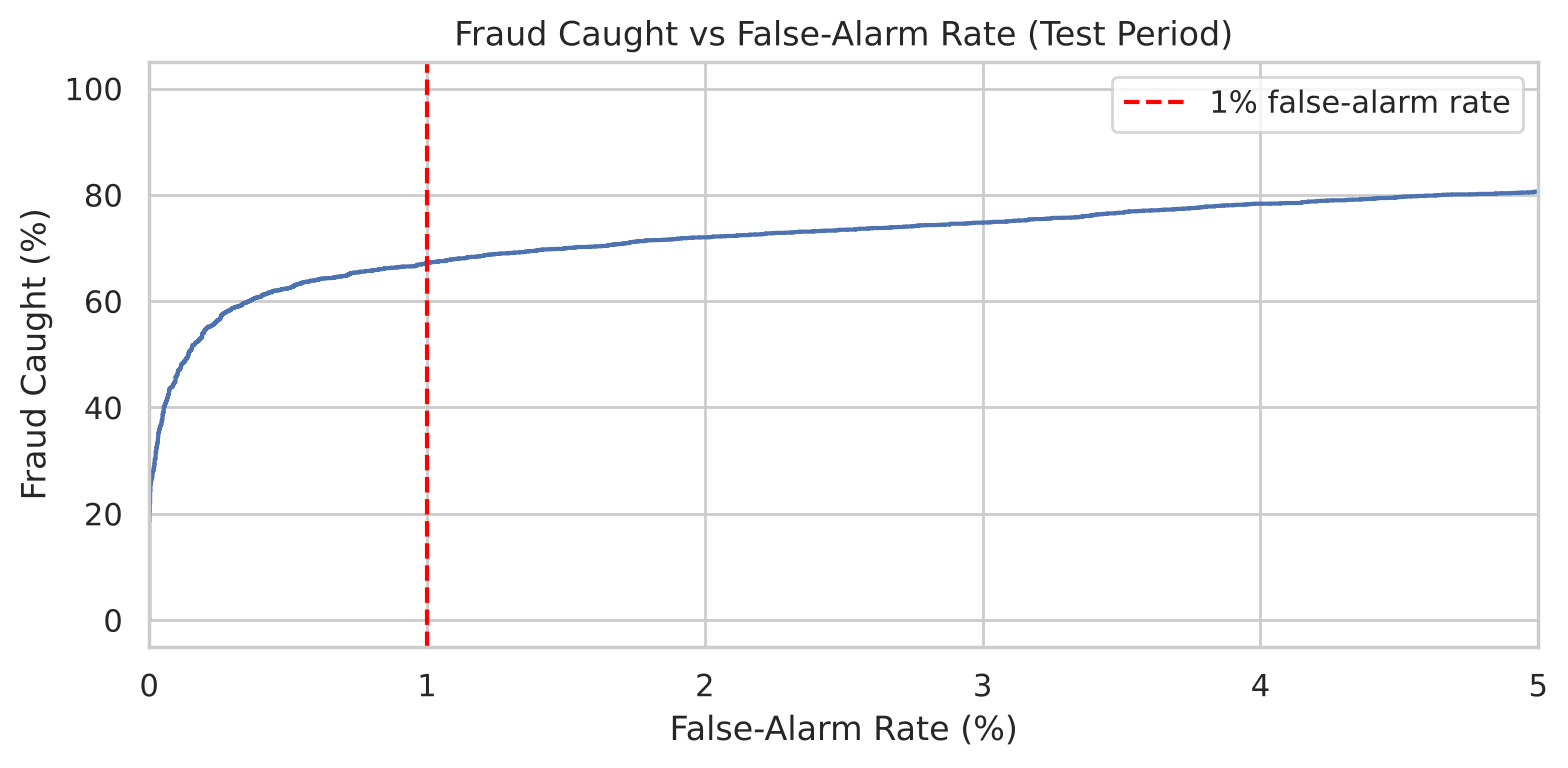

In [36]:
# Share of fraud caught at each false-alarm rate (zoomed in on low rates)
fpr, tpr, _ = roc_curve(y_test, test_scores)

plt.figure(figsize=(8, 4))
plt.plot(fpr * 100, tpr * 100)
plt.axvline(1, color="red", linestyle="--", label="1% false-alarm rate")
plt.xlim(0, 5)
plt.title("Fraud Caught vs False-Alarm Rate (Test Period)")
plt.xlabel("False-Alarm Rate (%)")
plt.ylabel("Fraud Caught (%)")
plt.legend()
plt.tight_layout()
plt.show()

## Step 11 — Explaining One Flagged Payment

Each alert can come with its reasons, which a fraud analyst needs before blocking a card. Below: the highest-scoring test payment and the features that pushed its score up the most.

In [37]:
# The most suspicious test payment
top_row = int(np.argmax(test_scores))
round(test_scores[top_row], 4), int(y_test[top_row])

(np.float64(1.0), 1)

In [38]:
# Its top 8 reasons (SHAP values, log-odds)
contributions = final_model.predict(X_test[top_row:top_row + 1], pred_contrib=True)[0, :-1]
reasons = pd.DataFrame({"Value": X_test[top_row], "SHAP": contributions}, index=features)
reasons.sort_values("SHAP", ascending=False).head(8).round(3)

,Value,SHAP
hist_uid_rate,1.000,7.748
hist_uid2_rate,1.000,5.156
hist_uid_days_since_fraud,12.198,2.600
hist_uid2_last_label,1.000,1.754
hist_uid_last_label,1.000,1.586
hist_uid_fraud,57.000,1.208
hist_uid2_days_since_fraud,12.198,0.752
hist_email_card_rate,1.000,0.629


## Step 12 — Save the Model

In [39]:
# Model file
final_model.save_model("models/fraud_lgbm.txt")

In [40]:
# Everything the scoring script needs to reproduce the features and alert levels
metadata = {
    "label_delay_days": LABEL_DELAY_DAYS,
    "features": features,
    "categories": categories,
    "trees": final_trees,
    "params": params,
    "flag_share_1pct_fpr": float(share_1pct_fpr),
    "flag_share_cost_optimal": float(share_cost_optimal),
    "validation_results": val_results.to_dict(),
    "test_results": test_results.to_dict(),
}

with open("models/metadata.json", "w") as f:
    json.dump(metadata, f)

## Step 13 — Comparison of All Versions

In [41]:
# Test-period results of every version (versions 1–4 from their notebooks)
comparison = pd.DataFrame({
    "Model": ["LightGBM, basic features", "+ fixed D dates, Optuna tuning, retrained", "Tuned LightGBM (beat CatBoost and the blend)",
              "+ customer history (1-day labels, future-aware features)", "+ customer history, past-only features, 7-day labels"],
    "Leakage-free": ["Yes", "Yes", "Yes", "No", "Yes"],
    "Test PR-AUC": [0.559, 0.677, 0.676, 0.811, test_results["PR-AUC"]],
    "Fraud caught at 1% false alarms": [np.nan, 0.613, 0.607, 0.746, test_results["Recall at 1% FPR"]],
}, index=["Version 1", "Version 2", "Version 3", "Version 4", "Final"])

comparison

,Model,Leakage-free,Test PR-AUC,Fraud caught at 1% false alarms
Version 1,"LightGBM, basic features",Yes,0.5590,NaN
Version 2,"+ fixed D dates, Optuna tuning, retrained",Yes,0.6770,0.6130
Version 3,Tuned LightGBM (beat CatBoost and the blend),Yes,0.6760,0.6070
Version 4,"+ customer history (1-day labels, future-aware...",No,0.8110,0.7460
Final,"+ customer history, past-only features, 7-day ...",Yes,0.7441,0.6717


**Findings**

**Final model, test period (scored once, leakage-free):**
- **Fraud caught at a 1% false-alarm rate: 67.2%**, up from 60.7% in version 3, the best leakage-free model before this one.
- **PR-AUC 0.744** (from 0.676) and **ROC-AUC 0.957**.
- **The alert levels chosen on validation held up on test.** "Flag the top 3.40%" was picked to give a 1% false-alarm rate on validation. On test it gave **1.08%** false alarms and caught **67.7%** of fraud (2,088 of 3,083).
- **Cost:** the cost-optimal level (top 10.5%, chosen on validation) catches **84.3%** of fraud for a total cost of **\$169,206**. That's **64% less than blocking nothing** (\$469,608), **41% less than the default 0.5 threshold** (\$285,844), and lower than every earlier leakage-free version.

**Why it is lower than version 4's 74.6%:** labels now arrive after 7 days instead of 1, and customer features no longer see future payments. **67.2% is the number to quote.** It's what the model would do under realistic rules.

**What drives the model:** the customer's known fraud history (`hist_uid_rate`, `hist_uid2_rate`) is by far the strongest signal, followed by the `C` counters, the card's first-use date (`D1n`) and the amount. The most suspicious test payment belonged to a customer with 57 known frauds, the last one 12 days earlier. The model can name that reason for every alert.

## Summary

| Version | Leakage-free | Test PR-AUC | Fraud caught at 1% false alarms | Lowest total cost |
|---|---|---|---|---|
| 1. Basic LightGBM | Yes | 0.559 | – | \$188,856 |
| 2. Better features + Optuna | Yes | 0.677 | 61.3% | \$216,251 |
| 3. Tuned LightGBM | Yes | 0.676 | 60.7% | \$203,773 |
| 4. Customer history (optimistic) | **No** | 0.811 | 74.6% | \$128,821 |
| **Final** | **Yes** | **0.744** | **67.2%** | **\$169,206** |

**Production checklist**
- Features use past payments only, proved in Step 4 and in `tests/test_features.py`.
- Fraud labels are used only once they are at least 7 days old. This was fixed before training, not tuned.
- Settings, tree count and both alert levels were chosen on validation. The test period was scored once.
- One shared feature module (`src/features.py`) is used by this notebook, `src/train.py` and `src/predict.py`.
- Category codes are saved with the model, so scoring uses exactly the same encoding.
- Every alert comes with its top reasons (SHAP).

**Limitations and next steps**
- **The customer ID is rebuilt** from anonymised columns (card + address + first-use date). A bank's real customer IDs would make the history features even more reliable.
- **Scoring is batch, not real time.** Real time would need a feature store that keeps each customer's running statistics and known labels up to date.
- **The 7-day label delay is an assumption.** If confirmations take longer (chargebacks can take weeks), recall would be lower. Retraining with the real delay is a one-line change (`LABEL_DELAY_DAYS`).
- **One validation block, not time-series cross-validation**, to keep training time reasonable. Each model was trained once, so differences under about 0.5 points are within noise.
- **Monitoring:** in production, track weekly recall at the alert level and the share of payments flagged, and retrain when they drift.